#  환경 설정

필요한 패키지를 설치합니다.

In [ ]:
# 필수 패키지 설치
! uv  pip install -q --upgrade langgraph langchain langchain_google_genai \
    langgraph-checkpoint-sqlite langchain-huggingface sentence-transformers

In [1]:
from dotenv import load_dotenv

load_dotenv()

True

# LLM 초기화

In [20]:
from langchain_core.rate_limiters import InMemoryRateLimiter  # 메모리 기반 속도 제한기 클래스
from langchain.chat_models import init_chat_model  # 모델명 문자열로 챗 모델을 초기화하는 함수

# 호출 제한 설정 (분당 10회)
rate_limiter = InMemoryRateLimiter(
    requests_per_second=0.167,   # 초당 허용 요청 수 (0.167회/초 ≈ 10회/분)
    check_every_n_seconds=0.1,   # 토큰(요청 허가) 사용 가능 여부를 0.1초마다 확인
    max_bucket_size=10           # 버킷에 누적 가능한 최대 토큰 수 (한 번에 몰아서 보낼 수 있는 최대 요청 수)
)

# LLM 초기화 (rate_limiter를 연결하여 모든 호출에 속도 제한 적용)
llm = init_chat_model(
    model="gpt-5-mini",          # 사용할 모델명
    rate_limiter=rate_limiter    # 위에서 생성한 속도 제한기 전달
)

print("✅ LLM 초기화 완료")

✅ LLM 초기화 완료


---

#  SqliteSaver - 영구 메모리

## 🎯 학습 목표
- 대화를 파일에 영구 저장하기
- 프로그램 재시작 후에도 기억 유지

### MemorySaver vs SqliteSaver

| 특성 | MemorySaver | SqliteSaver |
|------|-------------|-------------|
| 저장 위치 | RAM (메모리) | 파일 (.sqlite) |
| 지속성 | 세션 종료 시 삭제 | 영구 보관 |
| 용도 | 테스트, 임시 사용 | 실전 프로젝트 |

# SqliteSaver  세팅

In [4]:
! uv pip install -qU langgraph-checkpoint-sqlite

In [21]:
from langgraph.checkpoint.sqlite import SqliteSaver  # SQLite 기반 체크포인터 클래스
import sqlite3  # SQLite 데이터베이스 연결용 표준 라이브러리
from typing import Annotated  # 타입에 메타데이터(리듀서)를 부착하기 위한 도구
from typing_extensions import TypedDict  # 상태 스키마 정의용 딕셔너리 타입
from langgraph.graph import StateGraph, START, END  # 그래프 빌더와 시작/종료 노드 상수
from langgraph.graph.message import add_messages  # 메시지 리스트 누적 리듀서
from langgraph.checkpoint.memory import MemorySaver  # 인메모리 체크포인터 (이 코드에서는 미사용)
from langchain_core.messages import HumanMessage  # 사용자 메시지 클래스 (이 코드에서는 미사용)

# SQLite 데이터베이스 연결 (파일이 없으면 새로 생성)
# check_same_thread=False: 생성한 스레드 외 다른 스레드에서도 연결 사용 허용
conn = sqlite3.connect("conversation_history.sqlite", check_same_thread=False)

# LangGraph 체크포인트를 SQLite에 저장하는 체크포인터 생성
sqlite_memory = SqliteSaver(conn)

# Step 1: 상태 정의 (대화 메시지를 담는 구조)
class State(TypedDict):
    messages: Annotated[list, add_messages]  # add_messages 리듀서로 메시지를 덮어쓰지 않고 누적

# Step 2: LLM 호출 노드
def call_model(state: State):
    """사용자 메시지를 받아 LLM 응답 생성"""
    response = llm.invoke(state["messages"])  # 현재까지의 메시지 전체를 LLM에 전달
    return {"messages": response}  # 응답 메시지를 상태에 추가 (리듀서가 리스트에 누적)

# Step 3: 그래프 구성
builder = StateGraph(State)                  # 상태 스키마 기반 그래프 빌더 생성
builder.add_node("call_model", call_model)   # LLM 호출 노드 등록
builder.add_edge(START, "call_model")        # 시작점에서 call_model 노드로 연결

# 그래프 컴파일 시 SQLite 체크포인터 연결 (스레드별 대화 이력이 파일에 영구 저장됨)
persistent_graph = builder.compile(checkpointer=sqlite_memory)

# 완료 메시지 출력
print("✅ SQLite 기반 영구 메모리 그래프 생성 완료")
print("💾 파일 저장 위치: conversation_history.sqlite")

✅ SQLite 기반 영구 메모리 그래프 생성 완료
💾 파일 저장 위치: conversation_history.sqlite


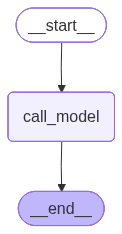

In [22]:
persistent_graph

## 실습: 영구 메모리로 대화하기

In [23]:
# 대화 설정 (thread_id로 대화 식별)
config = {"configurable": {"thread_id": "conversation-001"}}

# 첫 번째 질문
input_msg = HumanMessage("안녕하세요! 오늘은 비가 와요")
for chunk in persistent_graph.stream({"messages": [input_msg]}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

print("\n" + "="*50 + "\n")

================================ Human Message =================================

안녕하세요! 오늘은 비가 와요
================================== Ai Message ==================================

안녕하세요! 비가 오네요 — 우산 챙기셨나요?

간단한 안전팁(밖에 계시면)
- 우산·방수 옷·미끄럼 방지 신발 착용
- 전자기기는 방수팩이나 지퍼백에 보관
- 빗길 운전/보행 주의, 대중교통 이용 시 출발 시간 여유 두기
- 침수 위험 지역은 피하기

집에 계시면
- 따뜻한 음료(생강차, 허브티, 커피, 코코아)로 몸 녹이기
- 국물 요리나 찜 같은 포근한 음식 추천
- 영화·드라마·책·플레이리스트로 느긋하게 보내기
- 실내 스트레칭이나 가벼운 운동으로 활력 유지

원하시면 오늘 예상 강수량·시간대 등 날씨 예보를 알려드리거나, 비 오는 날 어울리는 음악·영화·레시피를 추천해드릴게요. 어떤 걸 원하시나요? (지역 알려주시면 정확한 일기예보 드릴게요.)




In [24]:
# 새로운 대화 시작
config = {"configurable": {"thread_id": "conversation-001"}}

msg = HumanMessage("이전 대화내용이 뭐지?")
for chunk in persistent_graph.stream({"messages": [msg]}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

print("\n" + "="*50 + "\n")


================================ Human Message =================================

이전 대화내용이 뭐지?
================================== Ai Message ==================================

지금까지 대화 요약입니다:

1) 사용자: "안녕하세요! 오늘은 비가 와요"  
   - 첫 답변 요청 전 초기 메시지.

2) 보조: 인사·우산·미끄럼 주의·전자기기 방수 권고, 집에 있으면 따뜻한 음료·음악·영화·책 제안. 날씨 예보나 비 오는 날 추천을 해줄지 물음.

3) 사용자: "이전 대화내용이 뭐지?"  
   - 보조가 요약 제공(대화 요약 및 전체 원문 보여주거나 추천 시작 가능 여부 질문).

4) 사용자: "이번 주 계획이 뭐예요?"  
   - 보조: 개인 일정은 없다고 답함(24/7 대기). 대신 사용자를 위한 주간 일정 제안 가능. 1) 업무/공부 중심 2) 균형 잡힌 계획 3) 주말 중심 4) 맞춤형(정보 요청) 중 선택해 달라고 안내.

5) 사용자: 다시 "안녕하세요! 오늘은 비가 와요"  
   - 보조가 우산·방수·빗길 주의 등 외출 팁과 집에서 할 것들(음료·국물 요리·영화·스트레칭) 제안. 날씨 예보·음악·영화·레시피 추천을 원하면 지역 알려 달라고 요청.

6) 사용자: 현재 질문: "이전 대화내용이 뭐지?" (이 메시지)

원하시면 대화 전체 원문을 그대로 보여드리거나(복사), 지금부터 날씨 예보·추천·주간 일정 중 무엇을 할지 바로 진행할게요. 무엇을 원하시나요?




In [14]:

# 추가 대화
followup = {"role": "user", "content": "이번 주 계획이 뭐예요?"}
for chunk in persistent_graph.stream({"messages": [followup]}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

print("\n💡 이 대화는 파일에 저장되었습니다!")
print("   프로그램을 재시작해도 유지됩니다.")

================================ Human Message =================================

이번 주 계획이 뭐예요?
================================== Ai Message ==================================

저는 사람처럼 개인적인 일정이 있는 건 아니에요 — 24/7 여기서 도와드릴 준비만 되어 있습니다. 대신 사용자의 목표와 상황에 맞춘 이번 주 일정(일/시간별 계획, 업무·공부·운동·식사·집안일 등)을 같이 만들어드릴 수 있어요.

원하시면 바로 예시 일정을 드릴게요. 다음 중 어떤 걸 원하시나요?
1) 업무/공부 중심 주간 계획
2) 균형 잡힌(일+휴식) 주간 계획
3) 편안한 주말 중심 계획(휴식·취미)
4) 직접 맞춤형(목표·우선순위·약속·가용 시간 알려주시면 세부 일정 작성)

원하시는 항목 번호와 추가로 알려주실 정보(주요 약속, 출근/등교 시간, 운동 빈도, 식사/요리 선호 등)를 알려주세요.

💡 이 대화는 파일에 저장되었습니다!
   프로그램을 재시작해도 유지됩니다.


# DB 저장 내용 확인

In [25]:
# 어떤 테이블이 만들어졌는지 확인
cursor = conn.cursor()
cursor.execute("SELECT name FROM sqlite_master WHERE type='table'")
print("테이블 목록:", cursor.fetchall())

# checkpoints 테이블에서 스레드별 체크포인트 개수 확인
cursor.execute("""
    SELECT thread_id, COUNT(*)
    FROM checkpoints
    GROUP BY thread_id
""")
for row in cursor.fetchall():
    print(f"thread_id: {row[0]} | 체크포인트 수: {row[1]}")

테이블 목록: [('checkpoints',), ('writes',)]
thread_id: conversation-001 | 체크포인트 수: 15
thread_id: persistent-001 | 체크포인트 수: 3


In [26]:
# 그래프 객체 없이 SqliteSaver에서 바로 최신 체크포인트 조회
config = {"configurable": {"thread_id": "conversation-001"}}

checkpoint_tuple = sqlite_memory.get_tuple(config)

# 체크포인트에서 메시지 추출
messages = checkpoint_tuple.checkpoint["channel_values"].get("messages", [])
print(f"저장된 메시지 수: {len(messages)}")
print("=" * 60)
for msg in messages:
    print(f"[{msg.type}] {msg.content}")

저장된 메시지 수: 10
[human] 안녕하세요! 오늘은 비가 와요
[ai] 안녕하세요! 비가 오네요 — 우산 챙기셨어요? 밖에 계시면 미끄러움이나 침수 구간 조심하시고, 전자기기 방수 대책(비닐봉투나 방수 케이스)도 해두세요. 대중교통 이용하거나 방수 신발 신는 것도 도움이 됩니다.

집에 계시면 따뜻한 음료(생강차, 허브티, 커피) 한 잔과 좋아하는 음악·영화·책으로 포근하게 보내는 것도 좋아요. 필요하시면 오늘 날씨 예보 알려드리거나 비 오는 날 어울리는 음악·영화·레시피 추천해드릴게요. 어떤 걸 원하세요?
[human] 이전 대화내용이 뭐지?
[ai] 지금까지 대화 요약입니다:

- 당신: "안녕하세요! 오늘은 비가 와요" (인사와 오늘 비 온다는 말)
- 저: 우산·미끄럼·전자기기 방수 주의 권고, 집에 있으면 따뜻한 음료·음악·영화·책으로 보내는 제안, 원하면 날씨 예보나 비 오는 날 어울리는 음악·영화·레시피 추천 가능하냐고 물음

원하시면 대화 전체 원문을 그대로 보여드리거나(원하시면 복사해 드릴게요) 바로 날씨 예보/추천을 시작할게요. 무엇을 원하시나요?
[human] 이번 주 계획이 뭐예요?
[ai] 저는 사람처럼 개인적인 일정이 있는 건 아니에요 — 24/7 여기서 도와드릴 준비만 되어 있습니다. 대신 사용자의 목표와 상황에 맞춘 이번 주 일정(일/시간별 계획, 업무·공부·운동·식사·집안일 등)을 같이 만들어드릴 수 있어요.

원하시면 바로 예시 일정을 드릴게요. 다음 중 어떤 걸 원하시나요?
1) 업무/공부 중심 주간 계획
2) 균형 잡힌(일+휴식) 주간 계획
3) 편안한 주말 중심 계획(휴식·취미)
4) 직접 맞춤형(목표·우선순위·약속·가용 시간 알려주시면 세부 일정 작성)

원하시는 항목 번호와 추가로 알려주실 정보(주요 약속, 출근/등교 시간, 운동 빈도, 식사/요리 선호 등)를 알려주세요.
[human] 안녕하세요! 오늘은 비가 와요
[ai] 안녕하세요! 비가 오네요 — 우산 챙기셨나요?

간단한 안전팁(밖에 계시면)
- 우산·방